# 02 – Classical baselines

Logistic Regression and Random Forest trained on the raw 187 signal samples. These scores are the reference that the deep models have to beat. All results in this notebook are on the **validation set**.

In [1]:
import sys
sys.path.append("..")

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.data import load_mitbih, split_train_val, SEED
from src.evaluate import (compute_metrics, per_class_table, summary_row,
                          save_results, plot_confusion_matrix, FIG_DIR)

plt.rcParams.update({"font.size": 11, "axes.titlesize": 13, "axes.labelsize": 12})

In [2]:
X_train, y_train = load_mitbih("train")
X_tr, X_val, y_tr, y_val = split_train_val(X_train, y_train)
print("Train:", X_tr.shape, " Validation:", X_val.shape)

Train: (70043, 187)  Validation: (17511, 187)


## 1. Logistic Regression

The features are standardized inside a pipeline, so the scaler is fitted on the training split only. Two versions are compared: without and with `class_weight="balanced"`, which weights each class inversely to its frequency.

In [3]:
results = {}
predictions = {}

for name, class_weight in [("logreg", None), ("logreg_balanced", "balanced")]:
    params = {"model": "LogisticRegression", "scaler": "StandardScaler",
              "class_weight": class_weight, "max_iter": 2000, "random_state": SEED}
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight=class_weight, max_iter=2000, random_state=SEED),
    )

    start = time.time()
    model.fit(X_tr, y_tr)
    params["train_time_s"] = round(time.time() - start, 1)

    y_pred = model.predict(X_val)
    metrics = compute_metrics(y_val, y_pred)
    save_results(name, metrics, params)
    results[name] = metrics
    predictions[name] = y_pred
    print(f"{name}: macro F1 = {metrics['macro_f1']:.3f}  ({params['train_time_s']} s)")

logreg: macro F1 = 0.657  (7.2 s)


logreg_balanced: macro F1 = 0.482  (8.5 s)


In [4]:
pd.DataFrame([summary_row(name, m) for name, m in results.items()]).round(3)

,model,accuracy,balanced_accuracy,macro_f1,recall_S,recall_V,recall_F
0,logreg,0.914,0.588,0.657,0.449,0.337,0.281
1,logreg_balanced,0.675,0.772,0.482,0.692,0.739,0.852


Per-class results:

In [5]:
for name, m in results.items():
    print(name)
    display(per_class_table(m).round(3))

logreg


,precision,recall,f1,support
N,0.925,0.982,0.953,14494.0
S,0.820,0.449,0.581,445.0
V,0.634,0.337,0.440,1158.0
F,0.692,0.281,0.400,128.0
Q,0.936,0.890,0.913,1286.0


logreg_balanced


,precision,recall,f1,support
N,0.974,0.644,0.776,14494.0
S,0.152,0.692,0.249,445.0
V,0.298,0.739,0.425,1158.0
F,0.081,0.852,0.147,128.0
Q,0.720,0.935,0.813,1286.0


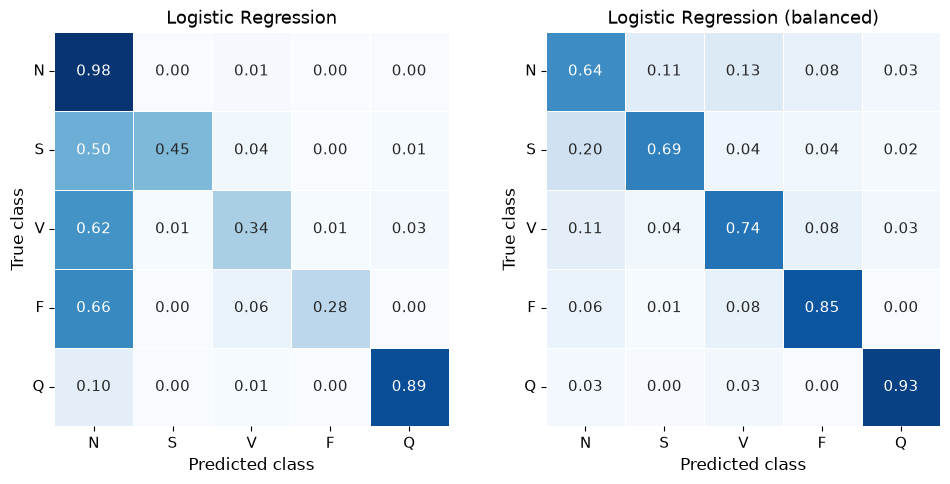

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
plot_confusion_matrix(y_val, predictions["logreg"], "Logistic Regression", ax=axes[0])
plot_confusion_matrix(y_val, predictions["logreg_balanced"], "Logistic Regression (balanced)", ax=axes[1])
fig.tight_layout()
fig.savefig(FIG_DIR / "cm_logreg.png", dpi=200)
plt.show()

## 2. Random Forest

An ensemble of 200 decision trees, each trained on a bootstrap sample of the training data and a random subset of features at each split. Trees do not need feature scaling. Again compared without and with `class_weight="balanced"`.

In [7]:
for name, class_weight in [("rf", None), ("rf_balanced", "balanced")]:
    params = {"model": "RandomForestClassifier", "n_estimators": 200,
              "class_weight": class_weight, "random_state": SEED}
    model = RandomForestClassifier(n_estimators=200, class_weight=class_weight,
                                   n_jobs=-1, random_state=SEED)

    start = time.time()
    model.fit(X_tr, y_tr)
    params["train_time_s"] = round(time.time() - start, 1)

    y_pred = model.predict(X_val)
    metrics = compute_metrics(y_val, y_pred)
    save_results(name, metrics, params)
    results[name] = metrics
    predictions[name] = y_pred
    print(f"{name}: macro F1 = {metrics['macro_f1']:.3f}  ({params['train_time_s']} s)")

rf: macro F1 = 0.876  (17.8 s)


rf_balanced: macro F1 = 0.900  (5.9 s)


In [8]:
for name in ["rf", "rf_balanced"]:
    print(name)
    display(per_class_table(results[name]).round(3))

rf


,precision,recall,f1,support
N,0.975,0.998,0.986,14494.0
S,0.972,0.620,0.757,445.0
V,0.969,0.892,0.929,1158.0
F,0.918,0.609,0.732,128.0
Q,0.993,0.956,0.974,1286.0


rf_balanced


,precision,recall,f1,support
N,0.985,0.994,0.989,14494.0
S,0.907,0.746,0.819,445.0
V,0.950,0.936,0.943,1158.0
F,0.856,0.695,0.767,128.0
Q,0.991,0.976,0.983,1286.0


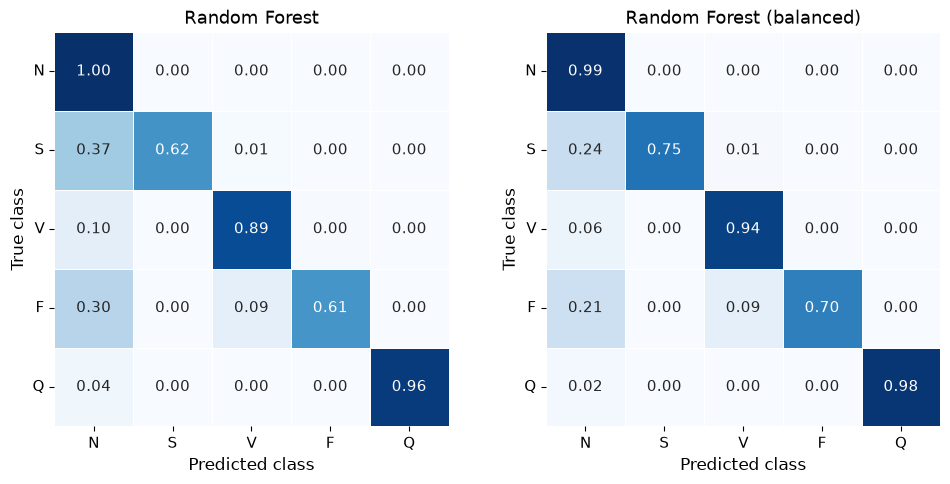

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
plot_confusion_matrix(y_val, predictions["rf"], "Random Forest", ax=axes[0])
plot_confusion_matrix(y_val, predictions["rf_balanced"], "Random Forest (balanced)", ax=axes[1])
fig.tight_layout()
fig.savefig(FIG_DIR / "cm_rf.png", dpi=200)
plt.show()

## 3. Baseline summary (validation set)

In [10]:
summary = pd.DataFrame([summary_row(name, m) for name, m in results.items()]).round(3)
summary.to_csv("../results/metrics/baselines_summary.csv", index=False)
summary

,model,accuracy,balanced_accuracy,macro_f1,recall_S,recall_V,recall_F
0,logreg,0.914,0.588,0.657,0.449,0.337,0.281
1,logreg_balanced,0.675,0.772,0.482,0.692,0.739,0.852
2,rf,0.976,0.815,0.876,0.620,0.892,0.609
3,rf_balanced,0.980,0.869,0.900,0.746,0.936,0.695
